Home Pratice matplotlib   15-10-2026

In [1]:
import matplotlib.pyplot as plt
import numpy as np 
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import LogisticRegression

In [2]:
df = pd.read_excel('water_pollution_dataset.xlsx')

In [3]:
df.head()

,Date,Country,City,Water Source,pH Level,Dissolved Oxygen (mg/L),Biological Oxygen Demand (BOD),Chemical Oxygen Demand (COD),Nitrates (mg/L),Phosphates (mg/L),Lead (mg/L),Mercury (mg/L),Pollution Index
0,2019-01-01,USA,New York,Lake,7.34,7.67,7.37,14.74,4.59,0.027,0.009,0.0016,23.266387
1,2019-01-01,USA,Los Angeles,Bay,7.20,5.57,11.65,23.30,4.85,0.198,0.010,0.0016,44.289412
2,2019-01-01,India,Mumbai,River,7.44,3.51,10.50,21.00,10.24,0.235,0.026,0.0011,64.906897
3,2019-01-01,India,Delhi,Lake,7.41,5.36,10.55,21.10,3.38,0.108,0.039,0.0022,46.426054
4,2019-01-01,China,Beijing,Bay,7.21,4.67,8.18,16.36,10.37,0.502,0.043,0.0012,53.340685


In [4]:
df.shape

(18260, 13)

In [5]:
df.columns

Index(['Date', 'Country', 'City', 'Water Source', 'pH Level',
       'Dissolved Oxygen (mg/L)', 'Biological Oxygen Demand (BOD)',
       'Chemical Oxygen Demand (COD)', 'Nitrates (mg/L)', 'Phosphates (mg/L)',
       'Lead (mg/L)', 'Mercury (mg/L)', 'Pollution Index'],
      dtype='str')

Linear Regression

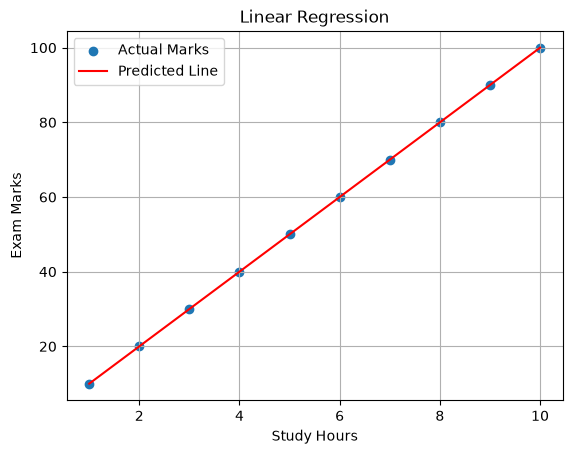

[50.]


In [6]:

# Study hours ka data le rahe hain (1 se 10 hours)
# reshape(-1, 1) data ko model ke liye sahi format mein karta hai
x = np.array([1,2,3,4,5,6,7,8,9,10]).reshape(-1,1)

# Har study hour ke corresponding marks
y = np.array([10,20,30,40,50,60,70,80,90,100])

# Linear Regression ka model bana rahe hain
model = LinearRegression()

# Model ko study hours aur marks ka pattern sikha rahe hain
model.fit(x, y)

# Diye gaye study hours ke marks predict kar rahe hain
predicted = model.predict(x)

# Actual marks ko dots ke form mein dikha rahe hain
plt.scatter(x, y, label='Actual Marks')

# Model ke predicted marks ki red line bana rahe hain
plt.plot(x, predicted, color='red', label='Predicted Line')

# X-axis par study hours ka naam
plt.xlabel('Study Hours')

# Y-axis par exam marks ka naam
plt.ylabel('Exam Marks')

# Graph ka title
plt.title('Linear Regression')

# Graph mein labels dikhane ke liye
plt.legend()

# Graph par grid dikhane ke liye
plt.grid(True)

# Graph ko screen par show kar rahe hain
plt.show()

# 5 hours study karne par marks predict kar rahe hain
print(model.predict([[5]]))


In [7]:
df.columns

Index(['Date', 'Country', 'City', 'Water Source', 'pH Level',
       'Dissolved Oxygen (mg/L)', 'Biological Oxygen Demand (BOD)',
       'Chemical Oxygen Demand (COD)', 'Nitrates (mg/L)', 'Phosphates (mg/L)',
       'Lead (mg/L)', 'Mercury (mg/L)', 'Pollution Index'],
      dtype='str')

   Country  Pollution Index  pH Level
0   Brazil        47.699473  7.003957
1    China        55.057600  6.998105
2  Germany        40.003063  6.997418
3    India        54.963180  7.003319
4      USA        39.960346  6.992193
   Country  Pollution Index  pH Level  Pollution Level
0   Brazil        47.699473  7.003957                0
1    China        55.057600  6.998105                1
2  Germany        40.003063  6.997418                0
3    India        54.963180  7.003319                1
4      USA        39.960346  6.992193                0
[0 0 0 0 0]
   Pollution Level  predicted
0                0          0
1                1          0
2                0          0
3                1          0
4                0          0


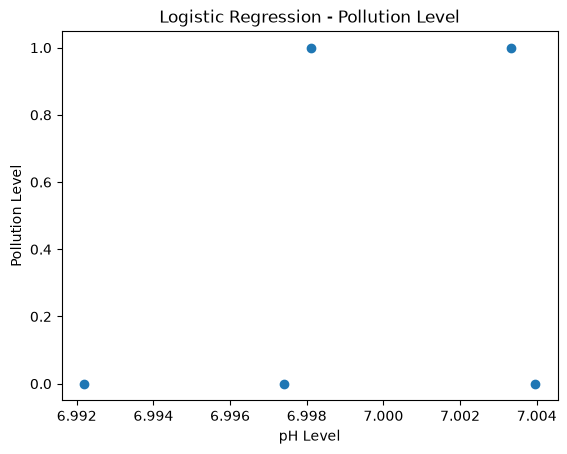

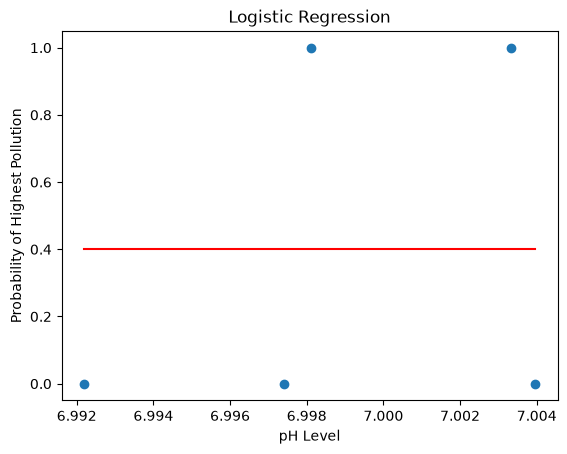

In [8]:
df_1 = df.groupby('Country').agg({'Pollution Index':'mean','pH Level':'mean'}).reset_index()
print(df_1)

df_1['Pollution Level'] = 0 
df_1.loc[df_1['Pollution Index'] > df_1['Pollution Index'].median(),'Pollution Level'] = 1 
print(df_1)

x = df_1[['pH Level']]
y = df_1['Pollution Level']

model = LogisticRegression()
model.fit(x,y)
predicted = model.predict(x)
print(predicted)

df_1['predicted'] = predicted
print(df_1[['Pollution Level','predicted']])

plt.scatter(df_1['pH Level'],df_1['Pollution Level'])
plt.xlabel('pH Level')
plt.ylabel('Pollution Level')
plt.title('Logistic Regression - Pollution Level')
plt.show()

x_line = np.linspace(
    df_1['pH Level'].min(),
    df_1['pH Level'].max(),
    100
)

y_line = model.predict_proba(
    pd.DataFrame({'pH Level': x_line})
)[:,-1]

plt.scatter(df_1['pH Level'],df_1['Pollution Level'])
plt.plot(x_line,y_line,color = 'red')

plt.xlabel('pH Level')
plt.ylabel('Probability of Highest Pollution')
plt.title('Logistic Regression')
plt.show()

In [9]:
pH_grid = np.linspace(X['pH Level'].min(), X['pH Level'].max(), 200)

X_curve = pd.DataFrame(
    X.mean().to_dict(),
    index=range(len(pH_grid))
)
X_curve['pH Level'] = pH_grid
X_curve = X_curve[features]

probability_high = logistic_model.predict_proba(X_curve)[:, 1]

plt.figure(figsize=(8, 5))
plt.scatter(X['pH Level'], y, alpha=0.15, label='Actual data')
plt.plot(pH_grid, probability_high, color='red', linewidth=2,
         label='Predicted probability')
plt.axhline(0.5, color='gray', linestyle='--', label='0.5 probability')
plt.xlabel('pH Level')
plt.ylabel('Probability of High Pollution')
plt.title('Logistic Regression')
plt.legend()
plt.grid(True)
plt.show()

NameError: name 'X' is not defined

In [ ]:
df.columns

Index(['Date', 'Country', 'City', 'Water Source', 'pH Level',
       'Dissolved Oxygen (mg/L)', 'Biological Oxygen Demand (BOD)',
       'Chemical Oxygen Demand (COD)', 'Nitrates (mg/L)', 'Phosphates (mg/L)',
       'Lead (mg/L)', 'Mercury (mg/L)', 'Pollution Index'],
      dtype='str')

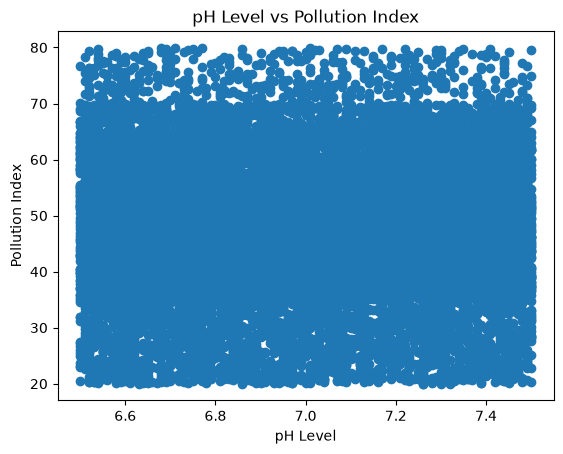

In [10]:
#  Q1: Scatter Plot

# Dataset: df (Water Pollution Dataset)

# Task: pH Level aur Pollution Index ke beech relationship dikhane ke liye scatter plot banao.

# Conditions:

# plt.scatter() use karna.

# X-axis: pH Level

# Y-axis: Pollution Index

# Title: pH Level vs Pollution Index

# X-axis aur Y-axis ke labels lagana.

# plt.show() se graph display karna.

x = df['pH Level']
y = df['Pollution Index']

plt.scatter(x, y)
plt.title('pH Level vs Pollution Index')
plt.xlabel('pH Level')
plt.ylabel('Pollution Index')
plt.show()

In [11]:
df.columns

Index(['Date', 'Country', 'City', 'Water Source', 'pH Level',
       'Dissolved Oxygen (mg/L)', 'Biological Oxygen Demand (BOD)',
       'Chemical Oxygen Demand (COD)', 'Nitrates (mg/L)', 'Phosphates (mg/L)',
       'Lead (mg/L)', 'Mercury (mg/L)', 'Pollution Index'],
      dtype='str')

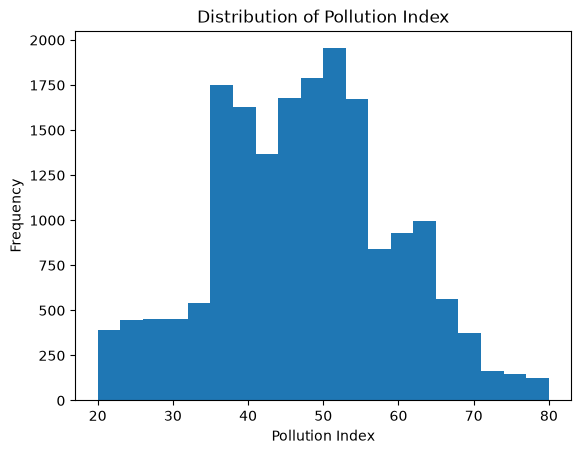

In [21]:
## Matplotlib Day 2 — Q2: Histogram

# **Dataset:** Water Pollution Dataset (`df`)

# **Task:** `Pollution Index` ki distribution dikhane ke liye histogram banao.

# **Conditions:**

# 1. `plt.hist()` use karna.
# 2. `bins=20` rakhna.
# 3. X-axis label: `Pollution Index`
# 4. Y-axis label: `Frequency`
# 5. Title: `Distribution of Pollution Index`
# 6. `plt.show()` se graph display karna.

# **Practice Rule:** Pehle khud code likhna. Notes dekh sakte ho. Agar atak jao, toh hint maang lena.

x = df['Pollution Index']
plt.hist(x,bins = 20 )
plt.xlabel('Pollution Index')
plt.ylabel('Frequency')
plt.title('Distribution of Pollution Index')
plt.show()

In [22]:
df.columns

Index(['Date', 'Country', 'City', 'Water Source', 'pH Level',
       'Dissolved Oxygen (mg/L)', 'Biological Oxygen Demand (BOD)',
       'Chemical Oxygen Demand (COD)', 'Nitrates (mg/L)', 'Phosphates (mg/L)',
       'Lead (mg/L)', 'Mercury (mg/L)', 'Pollution Index'],
      dtype='str')

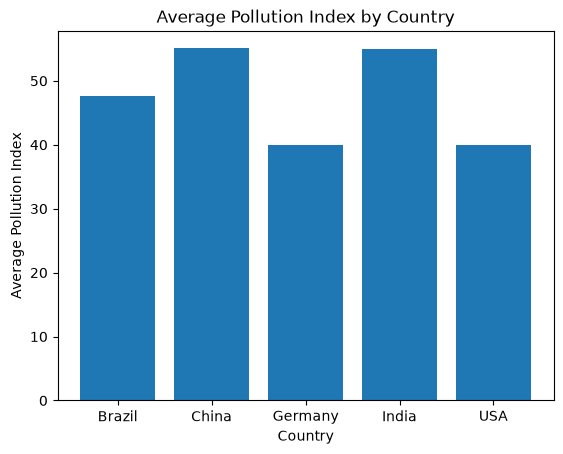

In [34]:
## Matplotlib Day 2 — Q3: Bar Chart

# **Dataset:** Water Pollution Dataset (`df`)

# **Task:** Har country ka average `Pollution Index` nikal kar bar chart banao.

# **Conditions:**
# 1. Pandas `groupby()` aur `mean()` use karna.
# 2. `plt.bar()` use karna.
# 3. X-axis label: `Country`
# 4. Y-axis label: `Average Pollution Index`
# 5. Title: `Average Pollution Index by Country`
# 6. `plt.show()` use karna.

# **Practice Rule:** Khud code likhna. Notes dekh sakte ho. Atko toh hint maangna.

df_2 = df.groupby('Country').agg({'Pollution Index':'mean'}).reset_index()
x = df_2['Country']
y = df_2['Pollution Index']
plt.bar(x,y)
plt.xlabel('Country')
plt.ylabel('Average Pollution Index')
plt.title('Average Pollution Index by Country')
plt.show()

In [35]:
df.columns

Index(['Date', 'Country', 'City', 'Water Source', 'pH Level',
       'Dissolved Oxygen (mg/L)', 'Biological Oxygen Demand (BOD)',
       'Chemical Oxygen Demand (COD)', 'Nitrates (mg/L)', 'Phosphates (mg/L)',
       'Lead (mg/L)', 'Mercury (mg/L)', 'Pollution Index'],
      dtype='str')

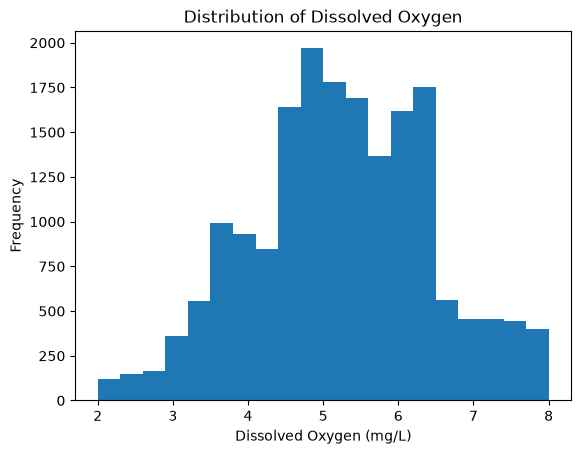

In [44]:
## Matplotlib Day 2 — Q4: Histogram

# **Dataset:** Water Pollution Dataset (`df`)

# **Task:** `Dissolved Oxygen (mg/L)` ki distribution dikhane ke liye histogram banao.

# **Conditions:**

# 1. `plt.hist()` use karna.
# 2. `bins=20` rakhna.
# 3. X-axis label: `Dissolved Oxygen (mg/L)`
# 4. Y-axis label: `Frequency`
# 5. Title: `Distribution of Dissolved Oxygen`
# 6. `plt.show()` use karna.

# **Practice Rule:** Khud code likhna. Notes dekh sakta hai. Atke toh hint maangna.

x = df['Dissolved Oxygen (mg/L)']
plt.hist(x,bins = 20)
plt.xlabel('Dissolved Oxygen (mg/L)')
plt.ylabel('Frequency')
plt.title('Distribution of Dissolved Oxygen')
plt.show()

In [48]:
df.columns

Index(['Date', 'Country', 'City', 'Water Source', 'pH Level',
       'Dissolved Oxygen (mg/L)', 'Biological Oxygen Demand (BOD)',
       'Chemical Oxygen Demand (COD)', 'Nitrates (mg/L)', 'Phosphates (mg/L)',
       'Lead (mg/L)', 'Mercury (mg/L)', 'Pollution Index'],
      dtype='str')

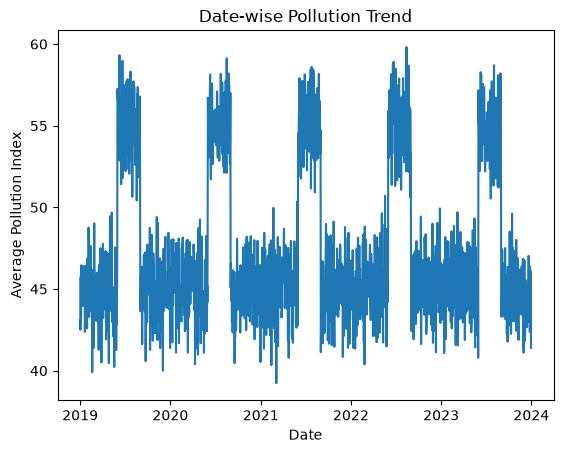

In [58]:
# Q5 — Line Graph 📈
# **Dataset:** Water Pollution Dataset (`df`)

# **Task:** Date ke according average `Pollution Index` ka trend dikhane ke liye line graph banao.

# **Conditions:**

# 1. Pandas `groupby()` aur `mean()` use karna.
# 2. `plt.plot()` use karna.
# 3. X-axis label: `Date`
# 4. Y-axis label: `Average Pollution Index`
# 5. Title: `Date-wise Pollution Trend`
# 6. `plt.show()` use karna.

# **Practice Rule:** Pehle khud code likhna. Atko toh hint maangna.

df_5 = df.groupby('Date').agg({'Pollution Index' : 'mean'}).reset_index()

x = df_5['Date']
y = df_5['Pollution Index']
plt.plot(x,y)
plt.xlabel('Date')
plt.ylabel('Average Pollution Index')
plt.title('Date-wise Pollution Trend')
plt.show()

In [59]:
df.columns

Index(['Date', 'Country', 'City', 'Water Source', 'pH Level',
       'Dissolved Oxygen (mg/L)', 'Biological Oxygen Demand (BOD)',
       'Chemical Oxygen Demand (COD)', 'Nitrates (mg/L)', 'Phosphates (mg/L)',
       'Lead (mg/L)', 'Mercury (mg/L)', 'Pollution Index'],
      dtype='str')

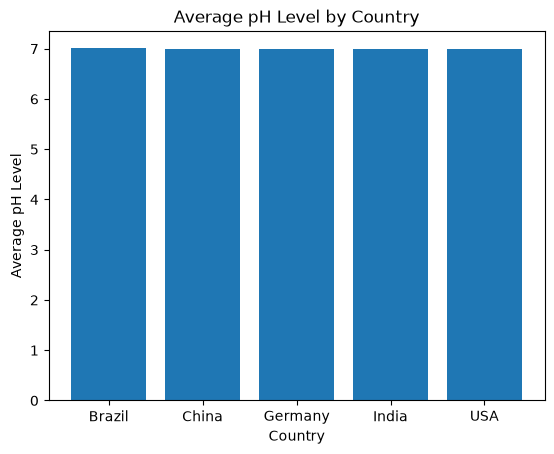

In [67]:
# ## Matplotlib Day 2 — Q6: Bar Chart

# **Task:** Har `Country` ka average `pH Level` dikhane ke liye bar chart banao.

# **Conditions:**

# 1. Pandas `groupby()` aur `mean()` use karna.
# 2. `plt.bar()` use karna.
# 3. X-axis label: `Country`
# 4. Y-axis label: `Average pH Level`
# 5. Title: `Average pH Level by Country`
# 6. `plt.show()` use karna.

# **Practice Rule:** Pehle khud code likhna. Notes dekh sakte ho. Atko toh hint maangna.

df_6 = df.groupby('Country').agg({'pH Level' : 'mean'}).reset_index()

x = df_6['Country']
y = df_6['pH Level']

plt.bar(x,y)
plt.xlabel('Country')
plt.ylabel('Average pH Level')
plt.title('Average pH Level by Country')
plt.show()

In [ ]:
# Q7. Scatter Plot: Dissolved Oxygen (mg/L) aur Pollution Index ke beech relationship dikhana hai.
# Conditions:
# 1. plt.scatter() use karna.
# 2. X-axis: Dissolved Oxygen (mg/L)
# 3. Y-axis: Pollution Index
# 4. X label, Y label, title aur plt.show() lagana.